In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

IMG_SIZE = 128
BATCH = 32  # passe à 16 si ton PC rame ou manque de RAM
AUTOTUNE = tf.data.AUTOTUNE

train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

label_map = {"NORMAL": 0, "PNEUMONIA": 1}
for d in (train_df, val_df, test_df):
    d["y"] = d["label"].map(label_map)

In [4]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

augment = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(15 / 360),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
])

def make_ds(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["y"].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=42).batch(BATCH)
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.batch(BATCH)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["y"])
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print(class_weight)

{0: 1.8497292418772564, 1: 0.6852223336676697}


In [5]:
from tensorflow.keras import layers, models

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    return x

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1./255)(inputs)       # normalisation dans le modèle
x = conv_block(x, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name="baseline_cnn")
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,465 (400.25 KB)

 Trainable params: 102,017 (398.50 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
model.fit(train_ds, validation_data=val_ds, epochs=1, class_weight=class_weight)

c:\Users\lenovo\pneumonia-detection-cnn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


129/129 ━━━━━━━━━━━━━━━━━━━━ 84s 598ms/step - accuracy: 0.7882 - auc: 0.8858 - loss: 0.4204 - precision: 0.9440 - recall: 0.7546 - val_accuracy: 0.7301 - val_auc: 0.8830 - val_loss: 0.9102 - val_precision: 0.7301 - val_recall: 1.0000


In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("../models/baseline_cnn.keras", monitor="val_loss", save_best_only=True),
] 

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,






































    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 86s 642ms/step - accuracy: 0.8522 - auc: 0.9290 - loss: 0.3339 - precision: 0.9581 - recall: 0.8338 - val_accuracy: 0.7301 - val_auc: 0.5061 - val_loss: 1.7545 - val_precision: 0.7301 - val_recall: 1.0000
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 84s 629ms/step - accuracy: 0.8622 - auc: 0.9374 - loss: 0.3164 - precision: 0.9595 - recall: 0.8469 - val_accuracy: 0.7301 - val_auc: 0.9356 - val_loss: 0.9310 - val_precision: 0.7301 - val_recall: 1.0000
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 85s 638ms/step - accuracy: 0.8683 - auc: 0.9439 - loss: 0.3029 - precision: 0.9612 - recall: 0.8539 - val_accuracy: 0.5262 - val_auc: 0.8224 - val_loss: 0.9896 - val_precision: 0.9555 - val_recall: 0.3682
Epoch 4/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 89s 667ms/step - accuracy: 0.8897 - auc: 0.9575 - loss: 0.2630 - precision: 0.9621 - recall: 0.8837 - val_accuracy: 0.2699 - val_auc: 0.7433 - val_loss: 1.9292 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/15
1

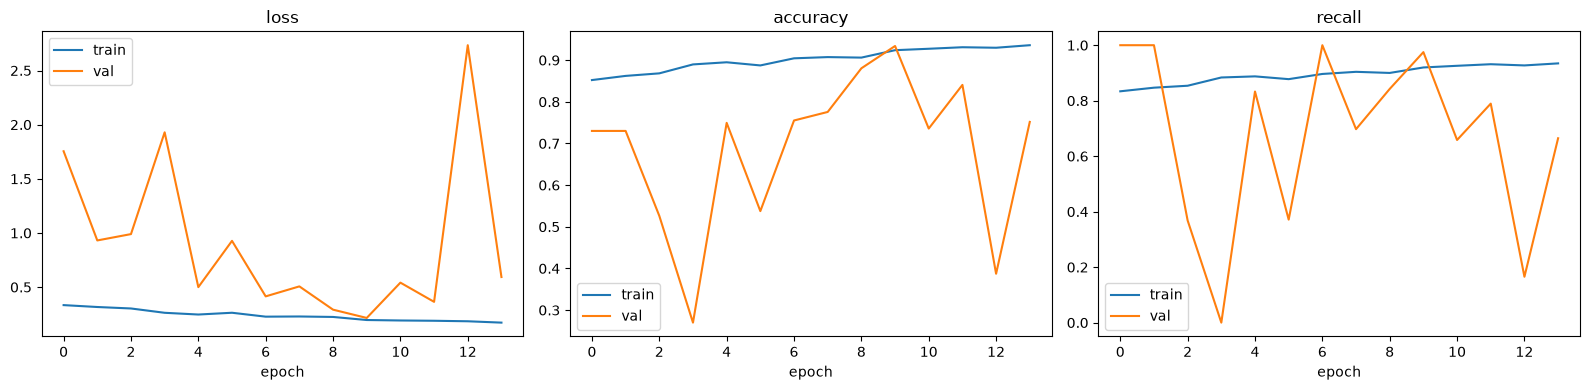

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, ["loss", "accuracy", "recall"]):
    ax.plot(history.history[m], label="train")
    ax.plot(history.history[f"val_{m}"], label="val")
    ax.set_title(m)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig("../models/baseline_curves.png", dpi=120)
plt.show()

In [9]:
res = model.evaluate(val_ds, return_dict=True)
print({k: round(v, 3) for k, v in res.items()})

28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 156ms/step - accuracy: 0.9339 - auc: 0.9755 - loss: 0.2154 - precision: 0.9370 - recall: 0.9750
{'accuracy': 0.934, 'auc': 0.975, 'loss': 0.215, 'precision': 0.937, 'recall': 0.975}
